In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("smartcart.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


In [10]:
df.shape

(2240, 22)

In [14]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing
### Handle missing values

In [32]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [34]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engineering
### 1. Age

In [37]:
df["Age"] = 2026 - df["Year_Birth"]

In [39]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


### 2. Customer joining days

In [75]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)

reference_date = df["Dt_Customer"].max()

df["Customer_joining_days"] = (reference_date - df["Dt_Customer"]).dt.days

In [77]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_joining_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


### 3. Spending

In [97]:
df["Total_Spending"] = df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']

In [99]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_joining_days,Total_Spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


### 4. Childrens

In [104]:
df["Total_children"] = df["Kidhome"] + df["Teenhome"]

In [106]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_joining_days,Total_Spending,Total_children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


### 5. Education

In [121]:
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [123]:
df["Education"] = df["Education"].replace({
    "Basic":"UnderGraduate", "2n Cycle":"UnderGraduate",
    "Graduation":"Graduate",
    "Master":"PostGraduate","PhD":"PostGraduate"
})

In [125]:
df["Education"].value_counts()

Education
Graduate         1127
PostGraduate      856
UnderGraduate     257
Name: count, dtype: int64

### 6. Maretial Status

In [128]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [135]:
df["Living_with"] = df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone","Widow":"Alone","Absurd":"Alone","YOLO":"Alone"
})

In [137]:
df["Living_with"].value_counts()

Living_with
Partner    1444
Alone       796
Name: count, dtype: int64

# Drop Columns

In [154]:
cols = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]

spending_cols = ['MntWines', 'MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds']

cols_to_drop = cols + spending_cols

In [156]:
df_cleaned = df.drop(columns=cols_to_drop)

df_cleaned.shape

(2240, 15)

In [158]:
df.shape

(2240, 27)

# Outliers

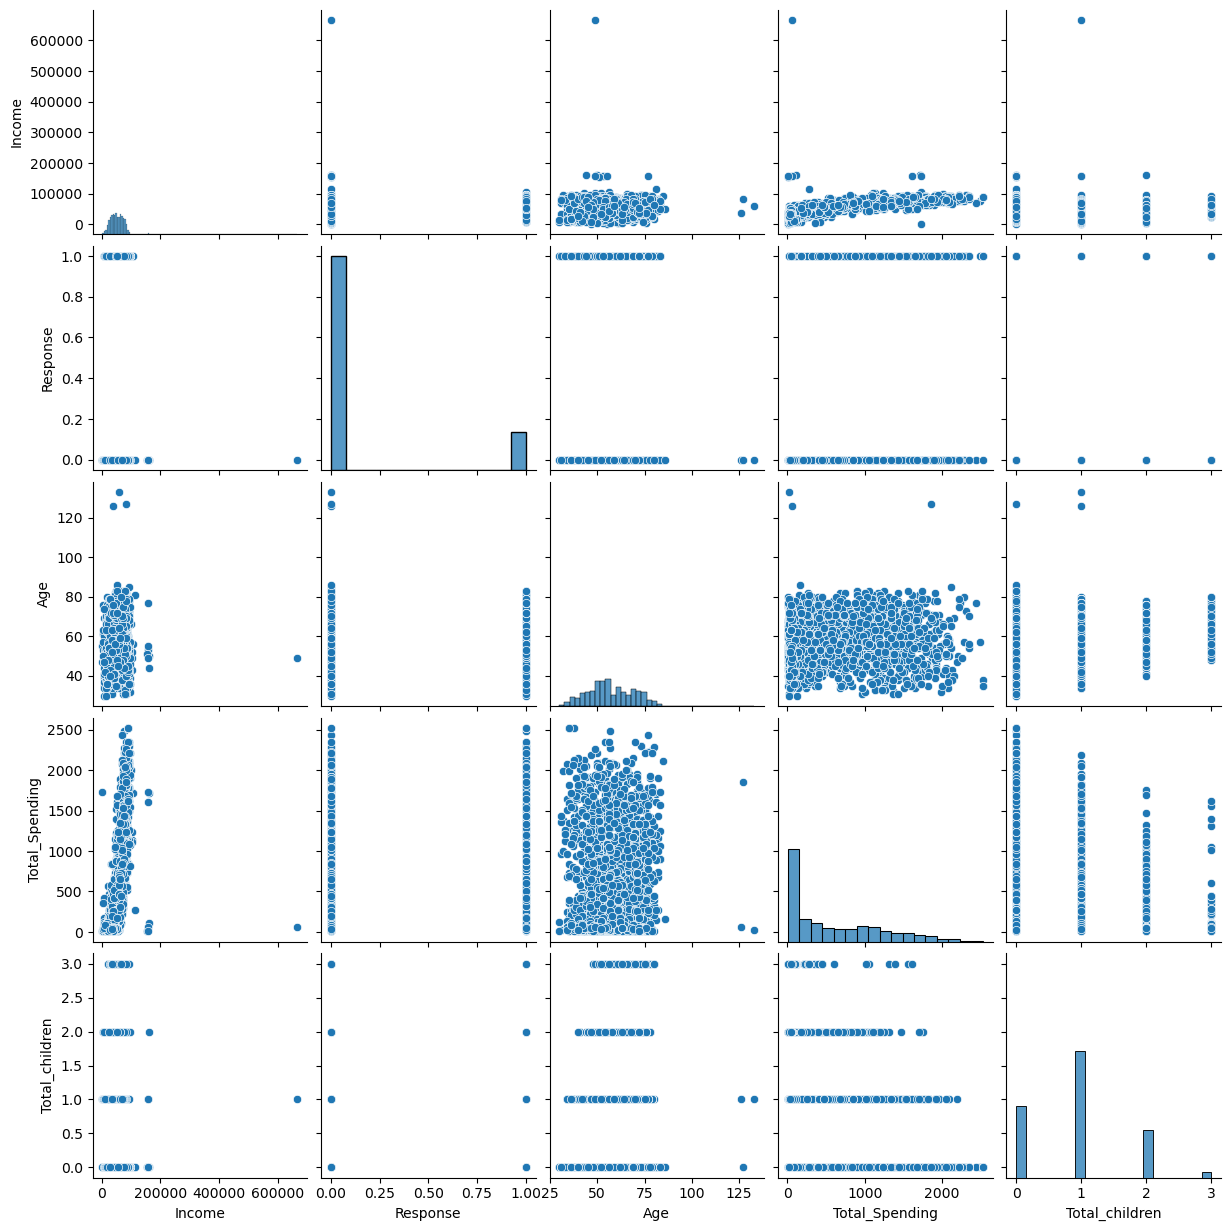

In [166]:
cols = ["Income","Response","Age","Total_Spending","Total_children"]

# relative plots of of some features 
# Pair Plots

sns.pairplot(df_cleaned[cols])

In [171]:
# Remove Outliers

print("data size with outliers = ",len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"]<90)]

df_cleaned = df_cleaned[(df_cleaned["Income"]<600_000)]

print("data size without outliers = ",len(df_cleaned))

data size with outliers =  2240
data size without outliers =  2236


# Heatmap

<Axes: >

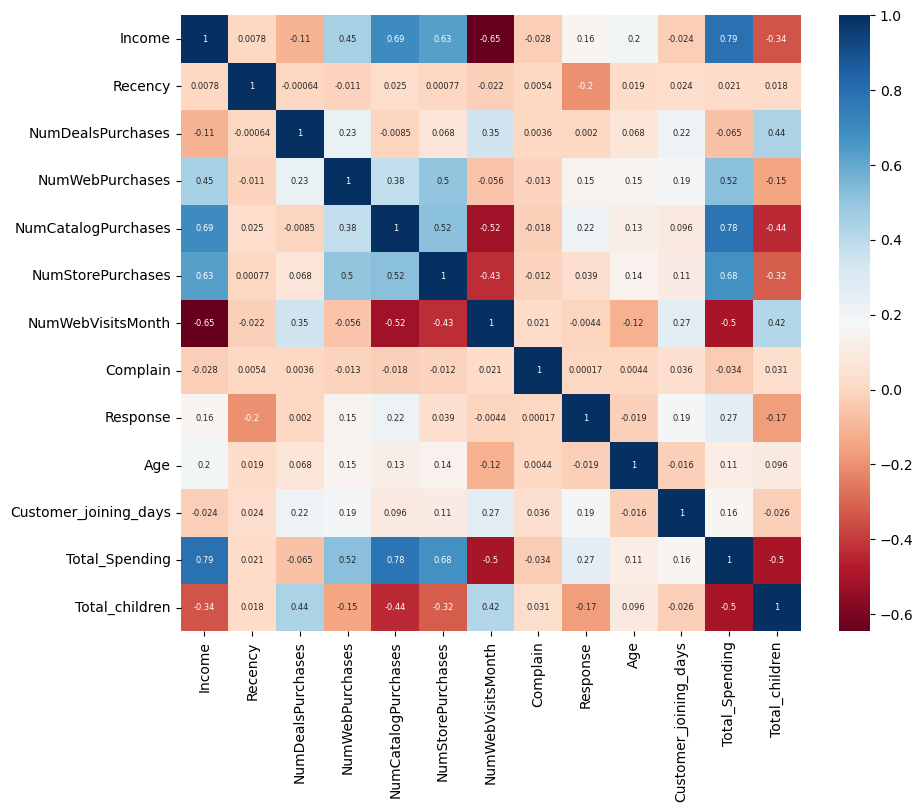

In [202]:
corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="RdBu"
    # cmap="coolware"
)

# Feature Encoding

In [205]:
from sklearn.preprocessing import OneHotEncoder

In [207]:
ohe = OneHotEncoder()

cat_cols = ["Education","Living_with"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [213]:
enc_df = pd.DataFrame(
    enc_cols.toarray(),
    columns = ohe.get_feature_names_out(cat_cols),
    index = df_cleaned.index
)

In [215]:
enc_df

,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_with_Alone,Living_with_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...
2235,1.0,0.0,0.0,0.0,1.0
2236,0.0,1.0,0.0,0.0,1.0
2237,1.0,0.0,0.0,1.0,0.0
2238,0.0,1.0,0.0,0.0,1.0


In [219]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols), enc_df], axis=1)
df_encoded.shape

(2236, 18)

In [221]:
df_cleaned.shape

(2236, 15)

# Scaling

In [228]:
from sklearn.preprocessing import StandardScaler

x = df_encoded

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

In [236]:
x_scaled.shape

(2236, 18)

# Visualization

In [240]:
# 2D
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

x_pca = pca.fit_transform(x_scaled)

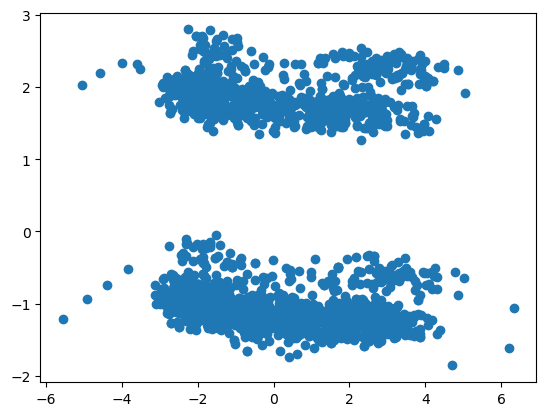

In [242]:
plt.scatter(x_pca[:,0],x_pca[:,1])

Text(0.5, 0.92, '3D projection')

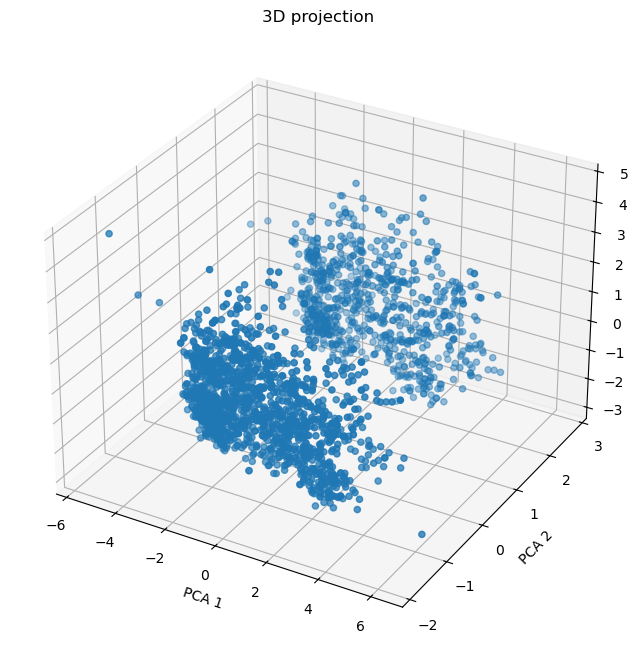

In [264]:
# 3D
fig = plt.figure(figsize=(10,8))

pca = PCA(n_components=3)

x_pca_3d = pca.fit_transform(x_scaled)

ax = fig.add_subplot(111,projection="3d")
ax.scatter(x_pca_3d[:,0],x_pca_3d[:,1],x_pca_3d[:,2])

ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
ax.set_title("3D projection")

# Analyze K value
### 1. Elbow method

In [295]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
# import warnings
# warnings.filterwarnings('ignore')

In [284]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(x_pca_3d)
    wcss.append(kmeans.inertia_)

In [299]:
knee = KneeLocator(
    range(1,11),
    wcss,
    curve='convex',
    direction='decreasing'
)

optimal_k = knee.elbow
print(optimal_k)

4


Text(0, 0.5, 'wcss')

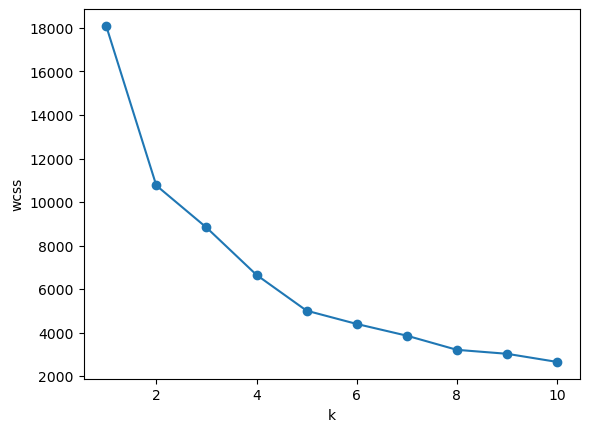

In [301]:
# plot

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel('k')
plt.ylabel('wcss')

### 2. Silhouette score

In [304]:
from sklearn.metrics import silhouette_score
scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x_pca_3d)
    score = silhouette_score(x_pca_3d, labels)
    scores.append(score)

Text(0, 0.5, 'silhouette_score')

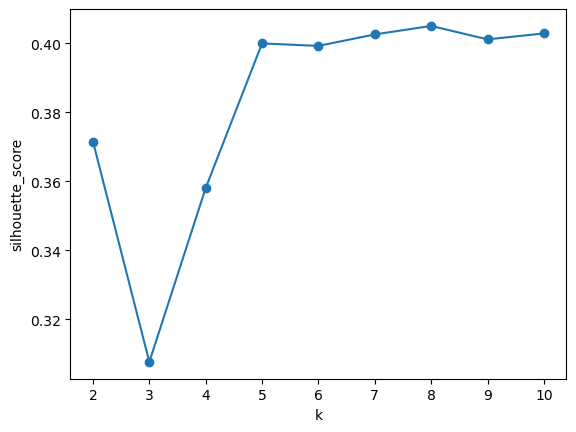

In [312]:
# plot
plt.plot(
    range(2,11),
    scores,
    marker='o'
)
plt.xlabel('k'),
plt.ylabel('silhouette_score')

### Combined plot

Text(0, 0.5, 'SS')

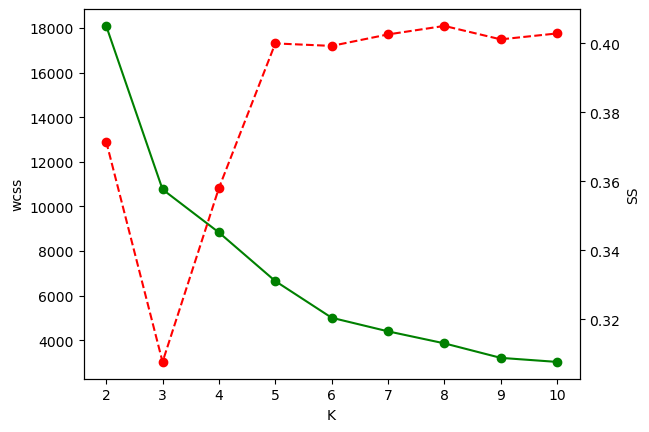

In [333]:
k_range = range(2,11)

fig, ax1 = plt.subplots(figure=(8,6))

ax1.plot(k_range, wcss[:len(k_range)], marker='o', c='g')
ax1.set_xlabel('K')
ax1.set_ylabel('wcss')

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker='o', c='r', linestyle='--')
# ax2.set_xlabel('K')
ax2.set_ylabel('SS')

# Clustering
### 1. KMeans

In [336]:
kmeans = KMeans(n_clusters=4, random_state=42)
labels_Kmeans = kmeans.fit_predict(x_pca_3d)

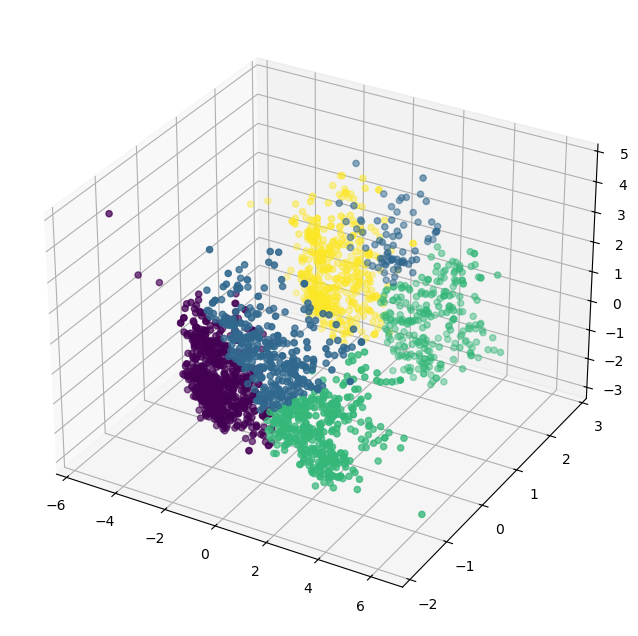

In [352]:
fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(111,projection="3d")
ax.scatter(x_pca_3d[:,0],x_pca_3d[:,1],x_pca_3d[:,2], c=labels_Kmeans)

### 2. AggloMerative Clustering

In [355]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agg = agg.fit_predict(x_pca_3d)

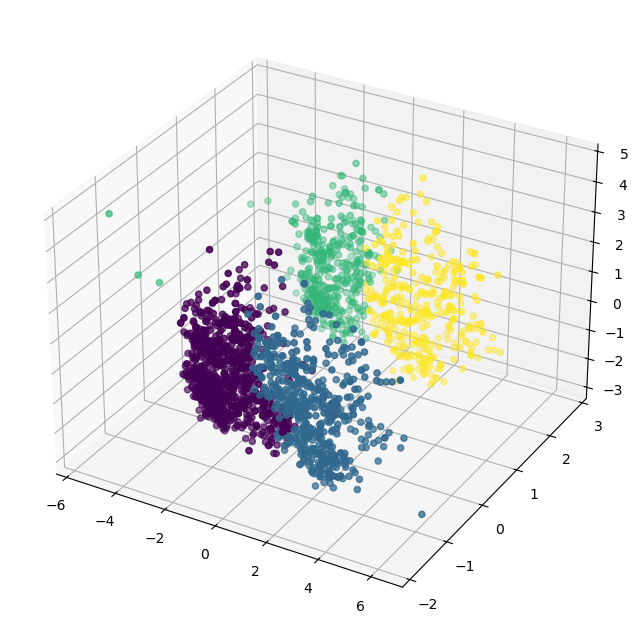

In [357]:
fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(111,projection="3d")
ax.scatter(x_pca_3d[:,0],x_pca_3d[:,1],x_pca_3d[:,2], c=labels_agg)

# Characterization of clusters

<Axes: xlabel='cluster', ylabel='count'>

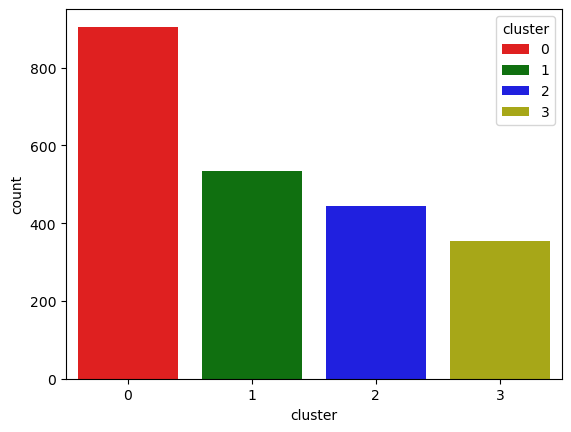

In [364]:
x['cluster'] = labels_agg

pal = ['r','g','b','y']

sns.countplot(x=x['cluster'], palette=pal, hue=x['cluster'])

<Axes: xlabel='Total_Spending', ylabel='Income'>

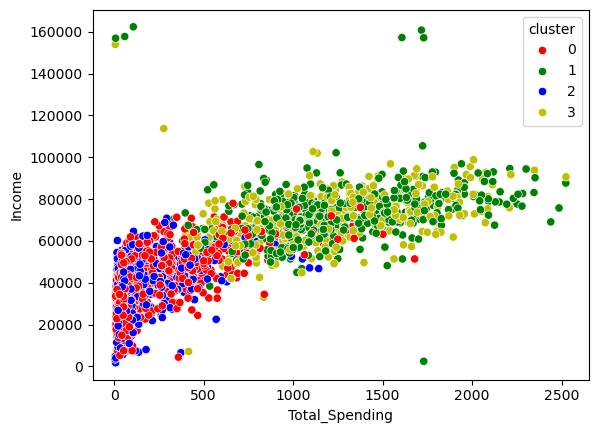

In [368]:
# Income and Spending pattern

sns.scatterplot(x=x["Total_Spending"],y=x["Income"], hue=x["cluster"], palette=pal)

# Cluster Summary

In [377]:
cluster_summary = x.groupby('cluster').mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_joining_days  Total_Spending  \
cluster        